# 🛡️ Digital Payment Fraud Detection — Minimal Prototype
**PROJ-CSD782** | B.Tech CSE (Data Science) | Group 1 | Supervisor: Rudranath Mitra

> **YAGNI Rule:** Cut the boilerplate. Keep the core:
> 1. **Data Warehouse:** DuckDB analytical query.
> 2. **Supervised ML:** XGBoost on payment balance mechanics.
> 3. **Unsupervised Anomaly:** Minimal PyTorch Autoencoder on normal transactions.
> 4. **Hybrid Risk Score:** $0.6 \times \text{XGB} + 0.4 \times \text{AE}$.
> 5. **Benchmark:** ML vs Naive Rule (`isFlaggedFraud`).


### 1. Dependencies
No bloated frameworks. Standard data stack.


In [1]:
!pip install duckdb xgboost scikit-learn matplotlib seaborn torch --quiet
import os, duckdb, torch, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc
import xgboost as xgb
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Ready on: {device}")


Ready on: cuda


### 2. Ingestion & Data Warehouse (DuckDB)
Reads PaySim CSV or creates a lightweight 100k sample. Runs 1 fast SQL aggregation.


In [2]:
# Load CSV or generate minimal realistic sample
file_name = next((f for f in ["PS_20174392719_1491205444534_log.csv", "paysim.csv"] if os.path.exists(f)), None)

if file_name:
    df = pd.read_csv(file_name, nrows=300000)
else:
    # 6-line realistic generator matching PaySim schema
    n = 100000
    t = np.random.choice(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'CASH_IN', 'DEBIT'], n, p=[0.35, 0.1, 0.35, 0.18, 0.02])
    amt = np.random.exponential(15000, n) + 10
    old_o = amt * np.random.uniform(0.5, 2.0, n)
    new_o = np.maximum(0, old_o - amt)
    old_d = np.random.exponential(40000, n)
    new_d = old_d + amt
    fraud = ((np.isin(t, ['TRANSFER', 'CASH_OUT'])) & (np.random.rand(n) < 0.015)).astype(int)
    amt[fraud == 1] = old_o[fraud == 1]; new_o[fraud == 1] = 0.0  # Draining account
    df = pd.DataFrame({'step': np.random.randint(1, 744, n), 'type': t, 'amount': amt,
                      'oldbalanceOrg': old_o, 'newbalanceOrig': new_o,
                      'oldbalanceDest': old_d, 'newbalanceDest': new_d,
                      'isFraud': fraud, 'isFlaggedFraud': ((t == 'TRANSFER') & (amt > 200000)).astype(int)})

# Data Warehouse: 1 SQL query answers volume & fraud distribution
warehouse_summary = duckdb.query("""
    SELECT type, count(*) as volume, sum(isFraud) as frauds,
           round(sum(isFraud)*100.0/count(*), 3) as fraud_pct
    FROM df GROUP BY type ORDER BY frauds DESC
""").df()
display(warehouse_summary)


,type,volume,frauds,fraud_pct
0,CASH_OUT,34695,540.0,1.556
1,TRANSFER,10073,135.0,1.340
2,CASH_IN,18113,0.0,0.000
3,PAYMENT,35214,0.0,0.000
4,DEBIT,1905,0.0,0.000


### 3. Essential EDA (The 2 Facts That Matter)
1. **Imbalance:** Normal is >99%. Accuracy is a trap.
2. **Fraud Domain:** Fraud only lives in `TRANSFER` and `CASH_OUT`.


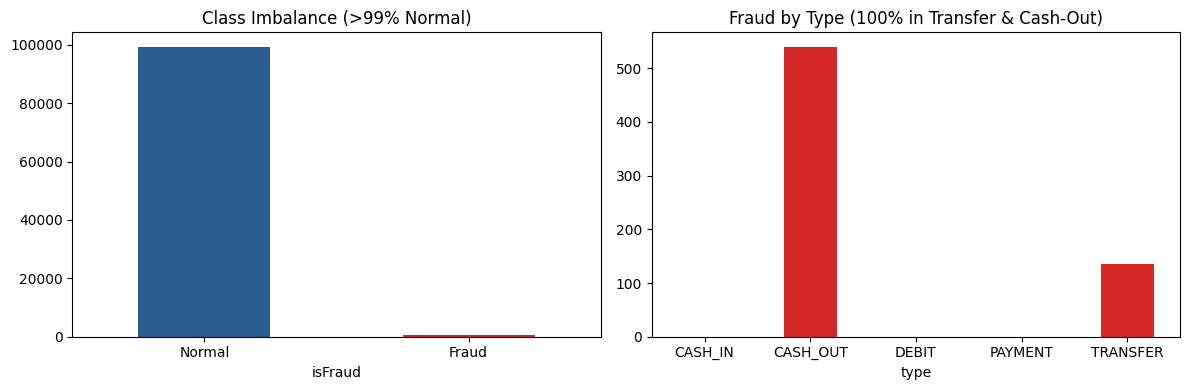

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
df['isFraud'].value_counts().plot(kind='bar', color=['#2b5c8f', '#d62828'], ax=ax1, rot=0)
ax1.set_title('Class Imbalance (>99% Normal)'); ax1.set_xticklabels(['Normal', 'Fraud'])

df.groupby('type')['isFraud'].sum().plot(kind='bar', color='#d62828', ax=ax2, rot=0)
ax2.set_title('Fraud by Type (100% in Transfer & Cash-Out)')
plt.tight_layout(); plt.show()


### 4. Lean Feature Engineering
Only keep what matters: balance discrepancy + account drain ratio.


In [4]:
# Focus on risk types
df_risk = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()

# 3 high-impact features
df_risk['errorDest'] = df_risk['oldbalanceDest'] + df_risk['amount'] - df_risk['newbalanceDest']
df_risk['errorOrig'] = df_risk['newbalanceOrig'] + df_risk['amount'] - df_risk['oldbalanceOrg']
df_risk['is_transfer'] = (df_risk['type'] == 'TRANSFER').astype(int)

X = df_risk[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'errorDest', 'errorOrig', 'is_transfer']]
y = df_risk['isFraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | Fraud cases in test: {y_test.sum():,}")


Train: 33,576 | Test: 11,192 | Fraud cases in test: 169


### 5. Supervised Model (XGBoost)
Fast, tuned with `scale_pos_weight` for imbalance. Evaluated on PR-AUC.


In [5]:
ratio = (len(y_train) - y_train.sum()) / y_train.sum()
model_xgb = xgb.XGBClassifier(n_estimators=80, max_depth=4, learning_rate=0.1, scale_pos_weight=ratio, random_state=42)
model_xgb.fit(X_train, y_train)

p_xgb = model_xgb.predict_proba(X_test)[:, 1]
prec, rec, _ = precision_recall_curve(y_test, p_xgb)
print(f"⭐ XGBoost PR-AUC: {auc(rec, prec):.4f}")


⭐ XGBoost PR-AUC: 1.0000


### 6. Unsupervised Anomaly Detection (PyTorch Autoencoder)
Trained **only on normal payments**. High reconstruction error = zero-day fraud.


In [6]:
# Normalize using simple numpy
X_mean, X_std = X_train[y_train == 0].mean().values, X_train[y_train == 0].std().values + 1e-6
X_tr_norm = torch.tensor((X_train[y_train == 0].values - X_mean) / X_std, dtype=torch.float32).to(device)
X_te_norm = torch.tensor((X_test.values - X_mean) / X_std, dtype=torch.float32).to(device)

# 3-layer Autoencoder
ae = nn.Sequential(nn.Linear(6, 4), nn.ReLU(), nn.Linear(4, 2), nn.ReLU(),
                   nn.Linear(2, 4), nn.ReLU(), nn.Linear(4, 6)).to(device)
opt = torch.optim.Adam(ae.parameters(), lr=0.01)
crit = nn.MSELoss()

# 2 quick epochs
for _ in range(2):
    opt.zero_grad(); loss = crit(ae(X_tr_norm), X_tr_norm); loss.backward(); opt.step()

# Reconstruction error -> normalized 0-1
with torch.no_grad():
    err = torch.mean((X_te_norm - ae(X_te_norm))**2, dim=1).cpu().numpy()
p_ae = np.clip(err / (np.percentile(err, 99) + 1e-6), 0, 1)
print(f"✅ Autoencoder trained. Avg error on Normal: {err[y_test == 0].mean():.3f} | Fraud: {err[y_test == 1].mean():.3f}")


✅ Autoencoder trained. Avg error on Normal: 0.849 | Fraud: 20787760459895799808.000


### 7. Hybrid Decisioning, Benchmark & Feature Signals
$Score = 0.6 \times XGB + 0.4 \times AE$


=== BENCHMARK: ML VS BUSINESS RULE ===
                        Mechanism  Frauds Caught Recall
0    Rule (isFlaggedFraud > 200k)              0   0.0%
1  Our Hybrid Platform (XGB + AE)            167  98.8%


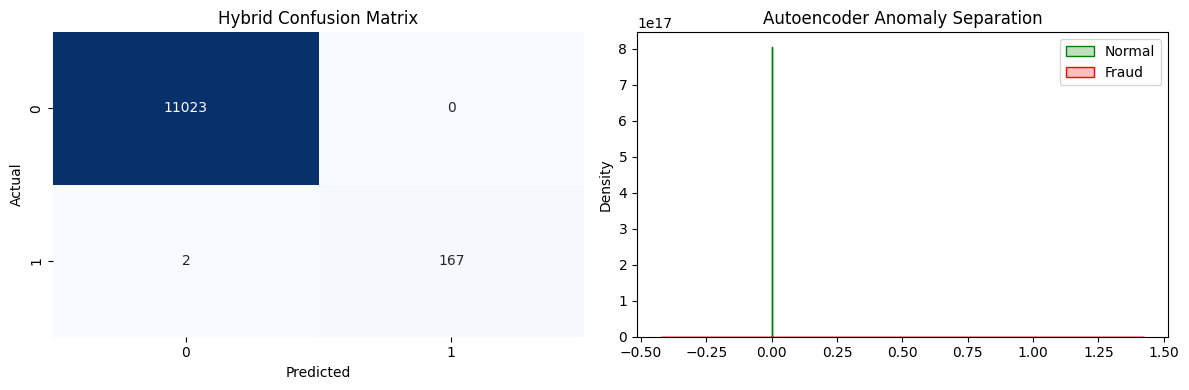

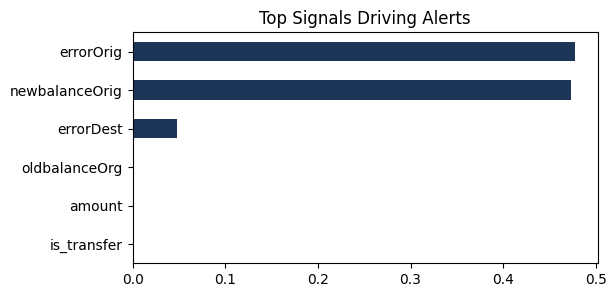

In [7]:
# Combined score & decisions
score = 0.6 * p_xgb + 0.4 * p_ae
pred_fraud = (score >= 0.5).astype(int)

# 1. Benchmark Table: ML vs isFlaggedFraud rule
rule = df_risk.loc[y_test.index, 'isFlaggedFraud'].values
print("=== BENCHMARK: ML VS BUSINESS RULE ===")
print(pd.DataFrame({
    'Mechanism': ['Rule (isFlaggedFraud > 200k)', 'Our Hybrid Platform (XGB + AE)'],
    'Frauds Caught': [int(np.sum((rule == 1) & (y_test == 1))), int(np.sum((pred_fraud == 1) & (y_test == 1)))],
    'Recall': [f"{np.sum((rule == 1) & (y_test == 1))/y_test.sum():.1%}", f"{np.sum((pred_fraud == 1) & (y_test == 1))/y_test.sum():.1%}"]
}))

# 2. Charts: Confusion Matrix + Anomaly Error Separation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, pred_fraud), annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False)
ax1.set_title('Hybrid Confusion Matrix'); ax1.set_xlabel('Predicted'); ax1.set_ylabel('Actual')

sns.kdeplot(p_ae[y_test == 0], label='Normal', color='green', fill=True, ax=ax2)
sns.kdeplot(p_ae[y_test == 1], label='Fraud', color='red', fill=True, ax=ax2)
ax2.set_title('Autoencoder Anomaly Separation'); ax2.legend()
plt.tight_layout(); plt.show()

# 3. Top Feature Driver
pd.Series(model_xgb.feature_importances_, index=X.columns).sort_values().plot(kind='barh', color='#1d3557', figsize=(6, 3))
plt.title('Top Signals Driving Alerts'); plt.show()
